# Lab 6: Deep Learning using PyTorch
## Experiment 2: Linear Regression using PyTorch

This notebook implements an end-to-end **Linear Regression** model using PyTorch's `torch.nn` and `torch.optim` modules.

### Objectives:
1. Synthesize a reproducible numerical dataset with known ground-truth parameters.
2. Construct PyTorch tensors and partition data into training and testing subsets (80:20).
3. Formulate a single-layer neural regression model using `torch.nn.Linear`.
4. Implement Mean Squared Error (`nn.MSELoss`) and Stochastic Gradient Descent (`optim.SGD`).
5. Execute a complete forward-backward training loop tracking loss across epochs.
6. Evaluate test metrics (MSE, RMSE, $R^2$ score) and visualize the fitted regression line against actual data.


---
### 1. Import Essential Libraries and Set Random Seeds
We import PyTorch, NumPy, Pandas, Matplotlib, and Scikit-Learn evaluation utilities, configuring paths for plot serialization.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score
import torch
import torch.nn as nn
import torch.optim as optim

# Set random seeds for strict reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Dynamic relative output directory
OUTPUT_DIR = Path("Lab6/outputs") if Path("Lab6").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output Directory: {OUTPUT_DIR.resolve()}")


Output Directory: /home/jeet/Desktop/Artificial_Intelligence/Lab6/outputs


---
### 2. Generate Reproducible Synthetic Dataset
We generate $N=250$ data points governed by the linear equation:
$$y = W_{\text{true}} \cdot x + b_{\text{true}} + \epsilon$$
- **True Weight ($W$)**: $3.5$
- **True Bias ($b$)**: $12.0$
- **Gaussian Noise ($\epsilon$)**: $\epsilon \sim \mathcal{N}(0, \sigma^2)$ where $\sigma = 1.2$


In [2]:
n_samples = 250
true_weight = 3.5
true_bias = 12.0

# Generate input feature x uniformly in [-3, 3]
x_np = np.random.uniform(-3.0, 3.0, size=(n_samples, 1)).astype(np.float32)
noise = np.random.normal(0, 1.2, size=(n_samples, 1)).astype(np.float32)
y_np = (true_weight * x_np + true_bias + noise).astype(np.float32)

print(f"Generated {n_samples} samples.")
print(f"x shape: {x_np.shape}, y shape: {y_np.shape}")
print(f"First 3 x values: {x_np[:3].flatten()}")
print(f"First 3 y values: {y_np[:3].flatten()}")


Generated 250 samples.
x shape: (250, 1), y shape: (250, 1)
First 3 x values: [-0.7527593  2.7042859  1.3919636]
First 3 y values: [ 8.349191 19.647184 16.336054]


---
### 3. Convert NumPy Data into PyTorch Tensors
PyTorch neural networks operate on tensors. We convert the NumPy arrays into 2D float tensors of shape `(N, 1)`.


In [3]:
X_tensor = torch.from_numpy(x_np)
y_tensor = torch.from_numpy(y_np)

print(f"X tensor shape: {X_tensor.shape}, dtype: {X_tensor.dtype}")
print(f"y tensor shape: {y_tensor.shape}, dtype: {y_tensor.dtype}")


X tensor shape: torch.Size([250, 1]), dtype: torch.float32
y tensor shape: torch.Size([250, 1]), dtype: torch.float32


---
### 4. Partition Data into Training and Testing Sets (80:20 Ratio)
We partition the 250 samples into 200 training instances ($80\%$) and 50 testing instances ($20\%$).


In [4]:
indices = np.random.permutation(n_samples)
train_idx, test_idx = indices[:200], indices[200:]

X_train, y_train = X_tensor[train_idx], y_tensor[train_idx]
X_test, y_test = X_tensor[test_idx], y_tensor[test_idx]

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set : {X_test.shape[0]} samples")


Training set: 200 samples
Testing set : 50 samples


---
### 5. Define Linear Regression Model using `torch.nn.Module`
A linear regression model implements the affine transformation:
$$\hat{y} = X W + b$$
In PyTorch, `torch.nn.Linear(in_features=1, out_features=1)` encapsulates the weight parameter matrix ($W$) and bias scalar ($b$).


In [5]:
class LinearRegressionModel(nn.Module):
    """Single-layer linear regression model."""
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x)

model = LinearRegressionModel()
print("Model Architecture:\n", model)

# Inspect uninitialized/randomized parameters
initial_w = model.linear.weight.item()
initial_b = model.linear.bias.item()
print(f"\nInitial Randomized Weight (W): {initial_w:.4f}")
print(f"Initial Randomized Bias   (b): {initial_b:.4f}")


Model Architecture:
 LinearRegressionModel(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)

Initial Randomized Weight (W): 0.7645
Initial Randomized Bias   (b): 0.8300


---
### 6. Define Loss Function (MSE) and Optimizer (SGD)
- **Mean Squared Error (MSE)** measures the average squared difference between predictions and ground-truth targets:
  $$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2$$
- **Stochastic Gradient Descent (SGD)** updates parameters in the negative gradient direction:
  $$\theta \leftarrow \theta - \eta \cdot \nabla_\theta \mathcal{L}$$
  where $\eta$ is the learning rate ($0.03$).


In [6]:
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.03)

print("Loss Function: Mean Squared Error (nn.MSELoss)")
print("Optimizer    : Stochastic Gradient Descent (optim.SGD, lr=0.03)")


Loss Function: Mean Squared Error (nn.MSELoss)
Optimizer    : Stochastic Gradient Descent (optim.SGD, lr=0.03)


---
### 7. Implement Complete PyTorch Training Loop
The training loop executes the canonical 5-step PyTorch optimization sequence across 150 epochs:
1. **Forward Pass**: Compute model predictions $\hat{y} = f(X)$.
2. **Loss Calculation**: Evaluate empirical discrepancy $\mathcal{L} = \text{MSE}(\hat{y}, y)$.
3. **Zero Gradients**: Reset previous accumulated gradients via `optimizer.zero_grad()`.
4. **Backward Pass**: Execute autograd backpropagation to compute $\frac{\partial \mathcal{L}}{\partial W}$ and $\frac{\partial \mathcal{L}}{\partial b}$ via `loss.backward()`.
5. **Optimizer Step**: Update parameters along the negative gradient vector via `optimizer.step()`.


In [7]:
epochs = 150
loss_history = []

for epoch in range(1, epochs + 1):
    model.train()

    # 1. Forward Pass
    predictions = model(X_train)

    # 2. Compute Loss
    loss = criterion(predictions, y_train)

    # 3. Clear Accumulated Gradients
    optimizer.zero_grad()

    # 4. Backward Pass (Autograd)
    loss.backward()

    # 5. Parameter Update
    optimizer.step()

    loss_history.append(loss.item())

    if epoch % 15 == 0 or epoch == 1:
        print(f"Epoch [{epoch:3d}/{epochs}] | Loss: {loss.item():.4f}")


Epoch [  1/150] | Loss: 145.5373
Epoch [ 15/150] | Loss: 24.8803
Epoch [ 30/150] | Loss: 5.1081
Epoch [ 45/150] | Loss: 1.9824
Epoch [ 60/150] | Loss: 1.4875
Epoch [ 75/150] | Loss: 1.4091
Epoch [ 90/150] | Loss: 1.3967
Epoch [105/150] | Loss: 1.3947
Epoch [120/150] | Loss: 1.3944
Epoch [135/150] | Loss: 1.3943
Epoch [150/150] | Loss: 1.3943


---
### 8. Visualize and Save Training Loss Curve
We inspect the convergence profile of the training loss across 150 epochs and export the figure to `Lab6/outputs/training_loss.png`.


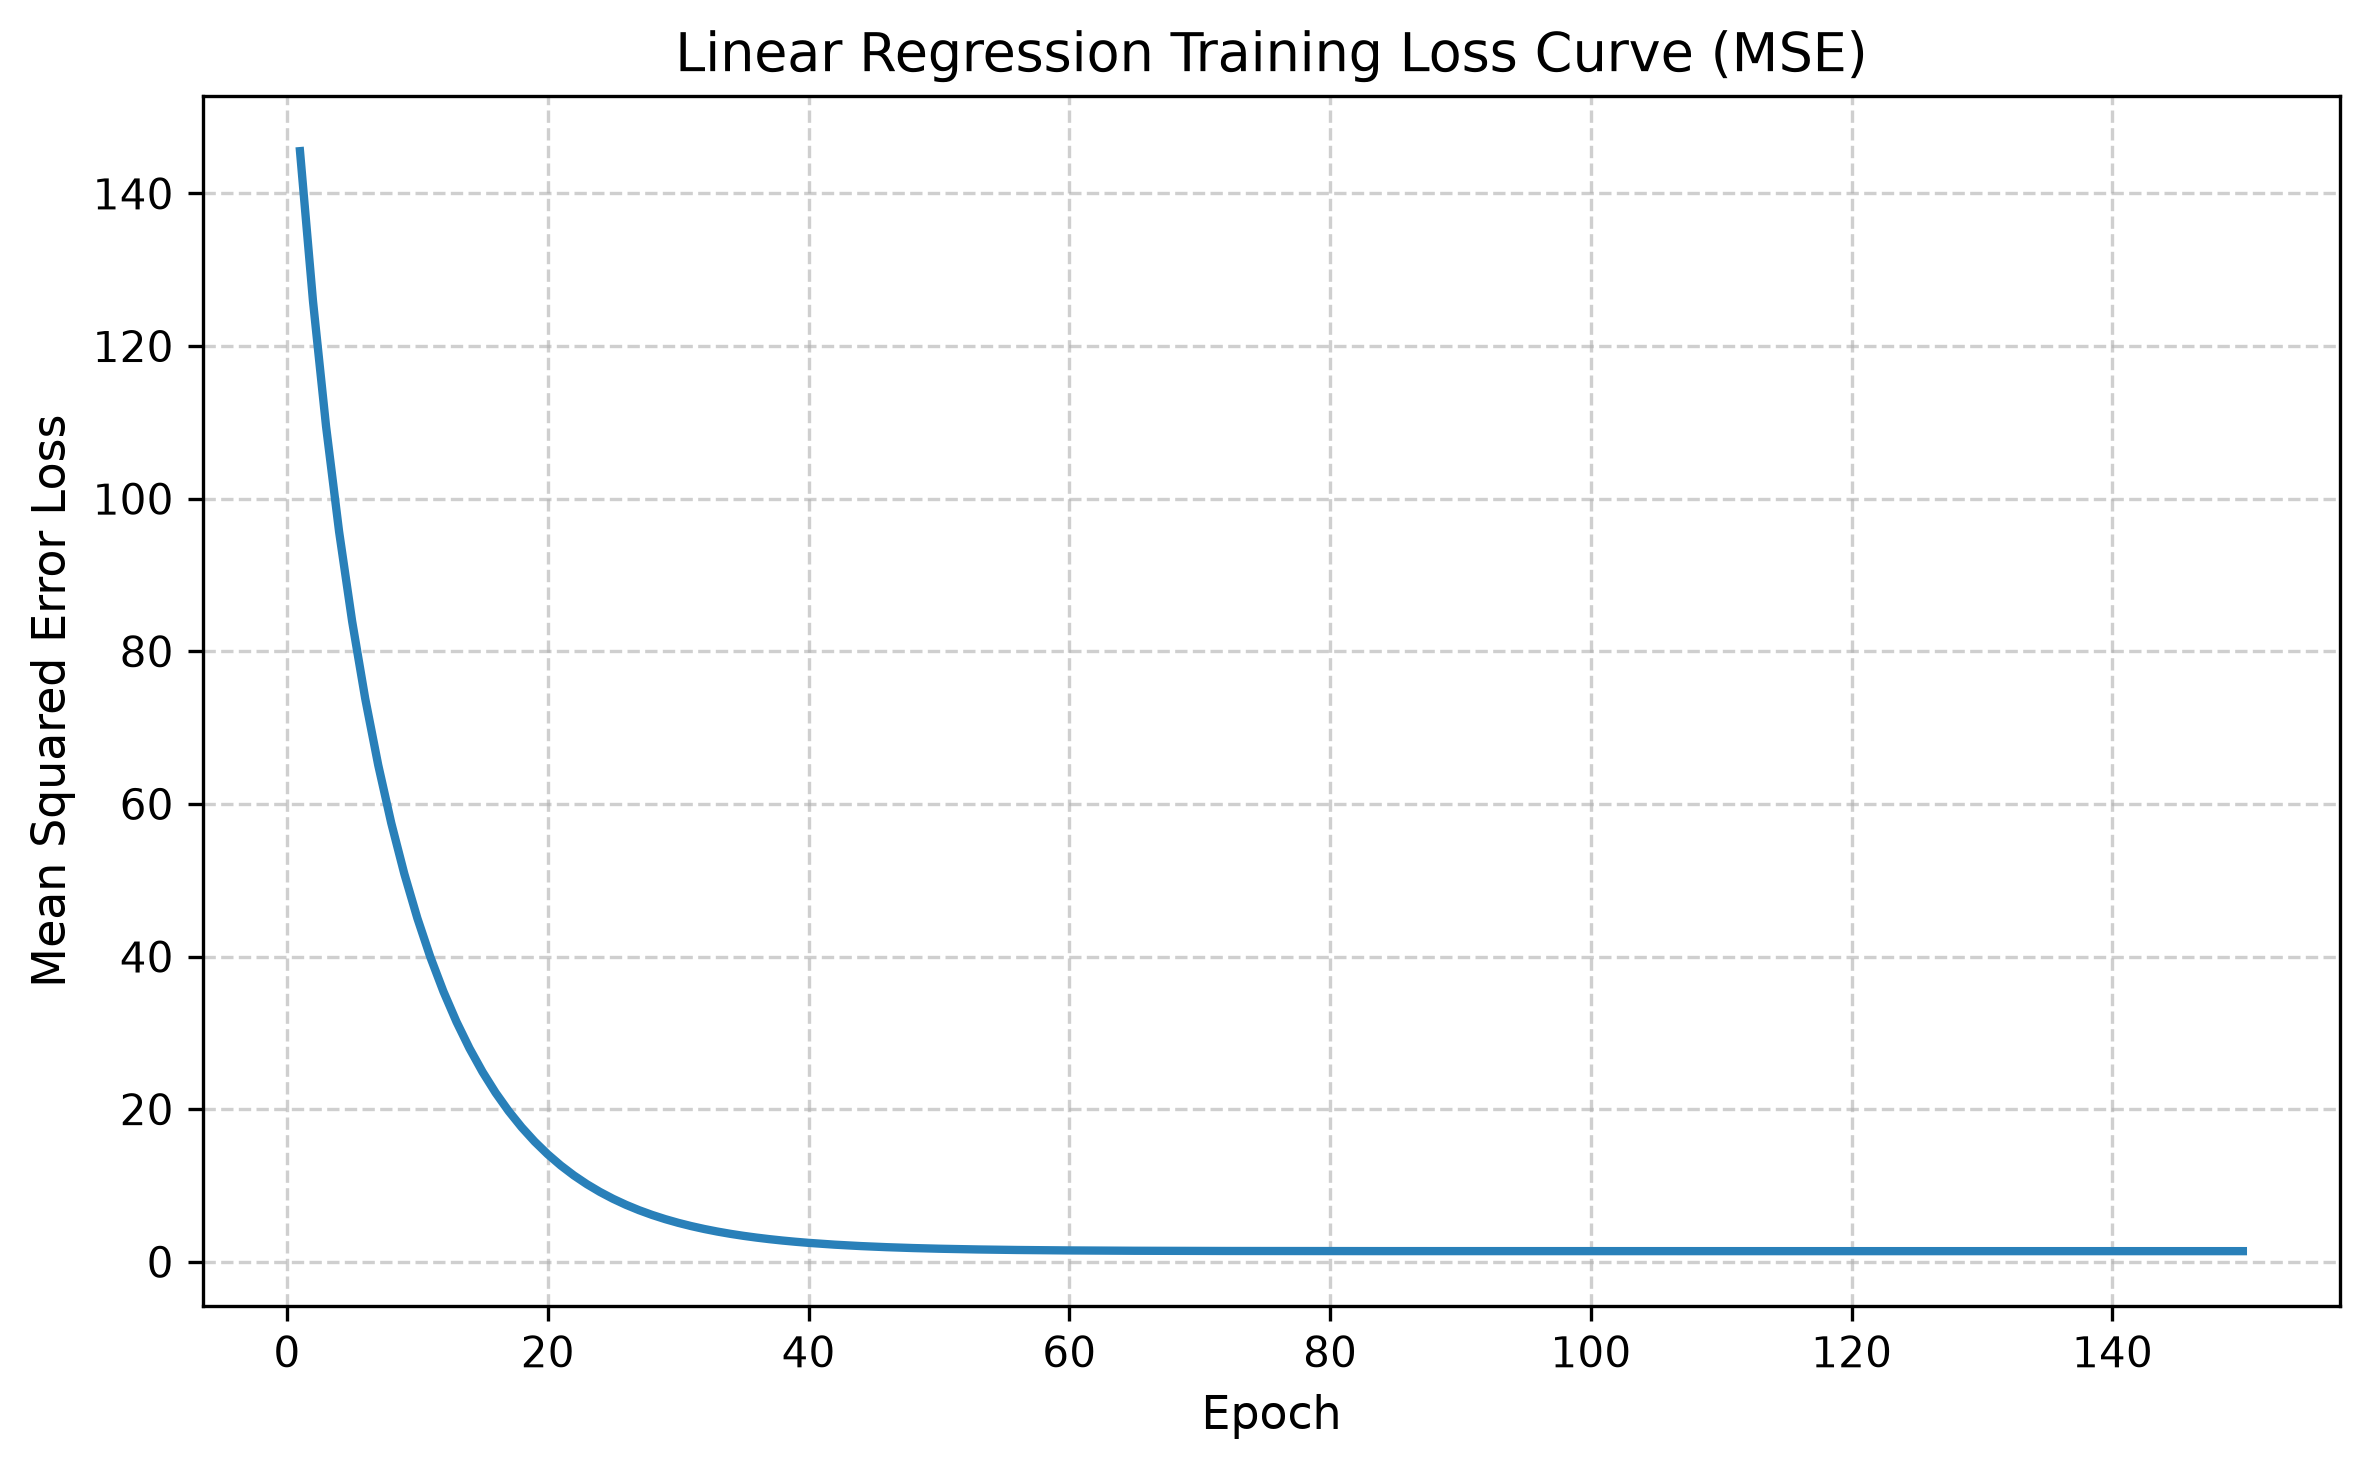

Training loss plot saved to: outputs/training_loss.png


In [8]:
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, epochs + 1), loss_history, color="#2980b9", lw=2)
plt.title("Linear Regression Training Loss Curve (MSE)", fontsize=13)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Mean Squared Error Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

loss_plot_path = OUTPUT_DIR / "training_loss.png"
plt.savefig(loss_plot_path)
plt.show()
print(f"Training loss plot saved to: {loss_plot_path}")


---
### 9. Model Evaluation on Unseen Test Data
We switch the model to evaluation mode (`model.eval()`) and disable gradient tracking (`torch.no_grad()`) to compute predictions on `X_test`. We evaluate Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the Coefficient of Determination ($R^2$ score).


In [9]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test)

test_mse = criterion(y_test_pred, y_test).item()
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test.numpy(), y_test_pred.numpy())

learned_w = model.linear.weight.item()
learned_b = model.linear.bias.item()

print("=== LINEAR REGRESSION TEST EVALUATION ===")
print(f"Learned Weight (W) : {learned_w:.4f}  (Ground Truth: {true_weight:.1f})")
print(f"Learned Bias   (b) : {learned_b:.4f}  (Ground Truth: {true_bias:.1f})")
print(f"Test MSE Loss      : {test_mse:.4f}")
print(f"Test RMSE          : {test_rmse:.4f}")
print(f"Test R^2 Score     : {test_r2:.4f} ({test_r2*100:.2f}%)")


=== LINEAR REGRESSION TEST EVALUATION ===
Learned Weight (W) : 3.4396  (Ground Truth: 3.5)
Learned Bias   (b) : 12.1807  (Ground Truth: 12.0)
Test MSE Loss      : 1.5420
Test RMSE          : 1.2418
Test R^2 Score     : 0.9619 (96.19%)


---
### 10. Actual vs. Predicted Values and Regression Fit Visualization
We contrast actual test observations against model predictions and overlay the fitted regression line against the testing scatter points, saving the plot to `Lab6/outputs/actual_vs_predicted.png`.


,Input (x),Actual Target (y),Predicted (y_hat),Residual Error
0,1.279,16.016001,16.582001,-0.566
1,-2.064,5.033000,5.082000,-0.048
2,0.671,14.967000,14.489000,0.478
3,0.657,15.471000,14.442000,1.029
4,2.118,17.757000,19.466000,-1.709
5,2.377,20.075001,20.355000,-0.280
6,-0.668,11.781000,9.883000,1.897
7,-0.680,9.140000,9.843000,-0.703
8,1.369,15.104000,16.891001,-1.787
9,1.565,17.613001,17.563000,0.050


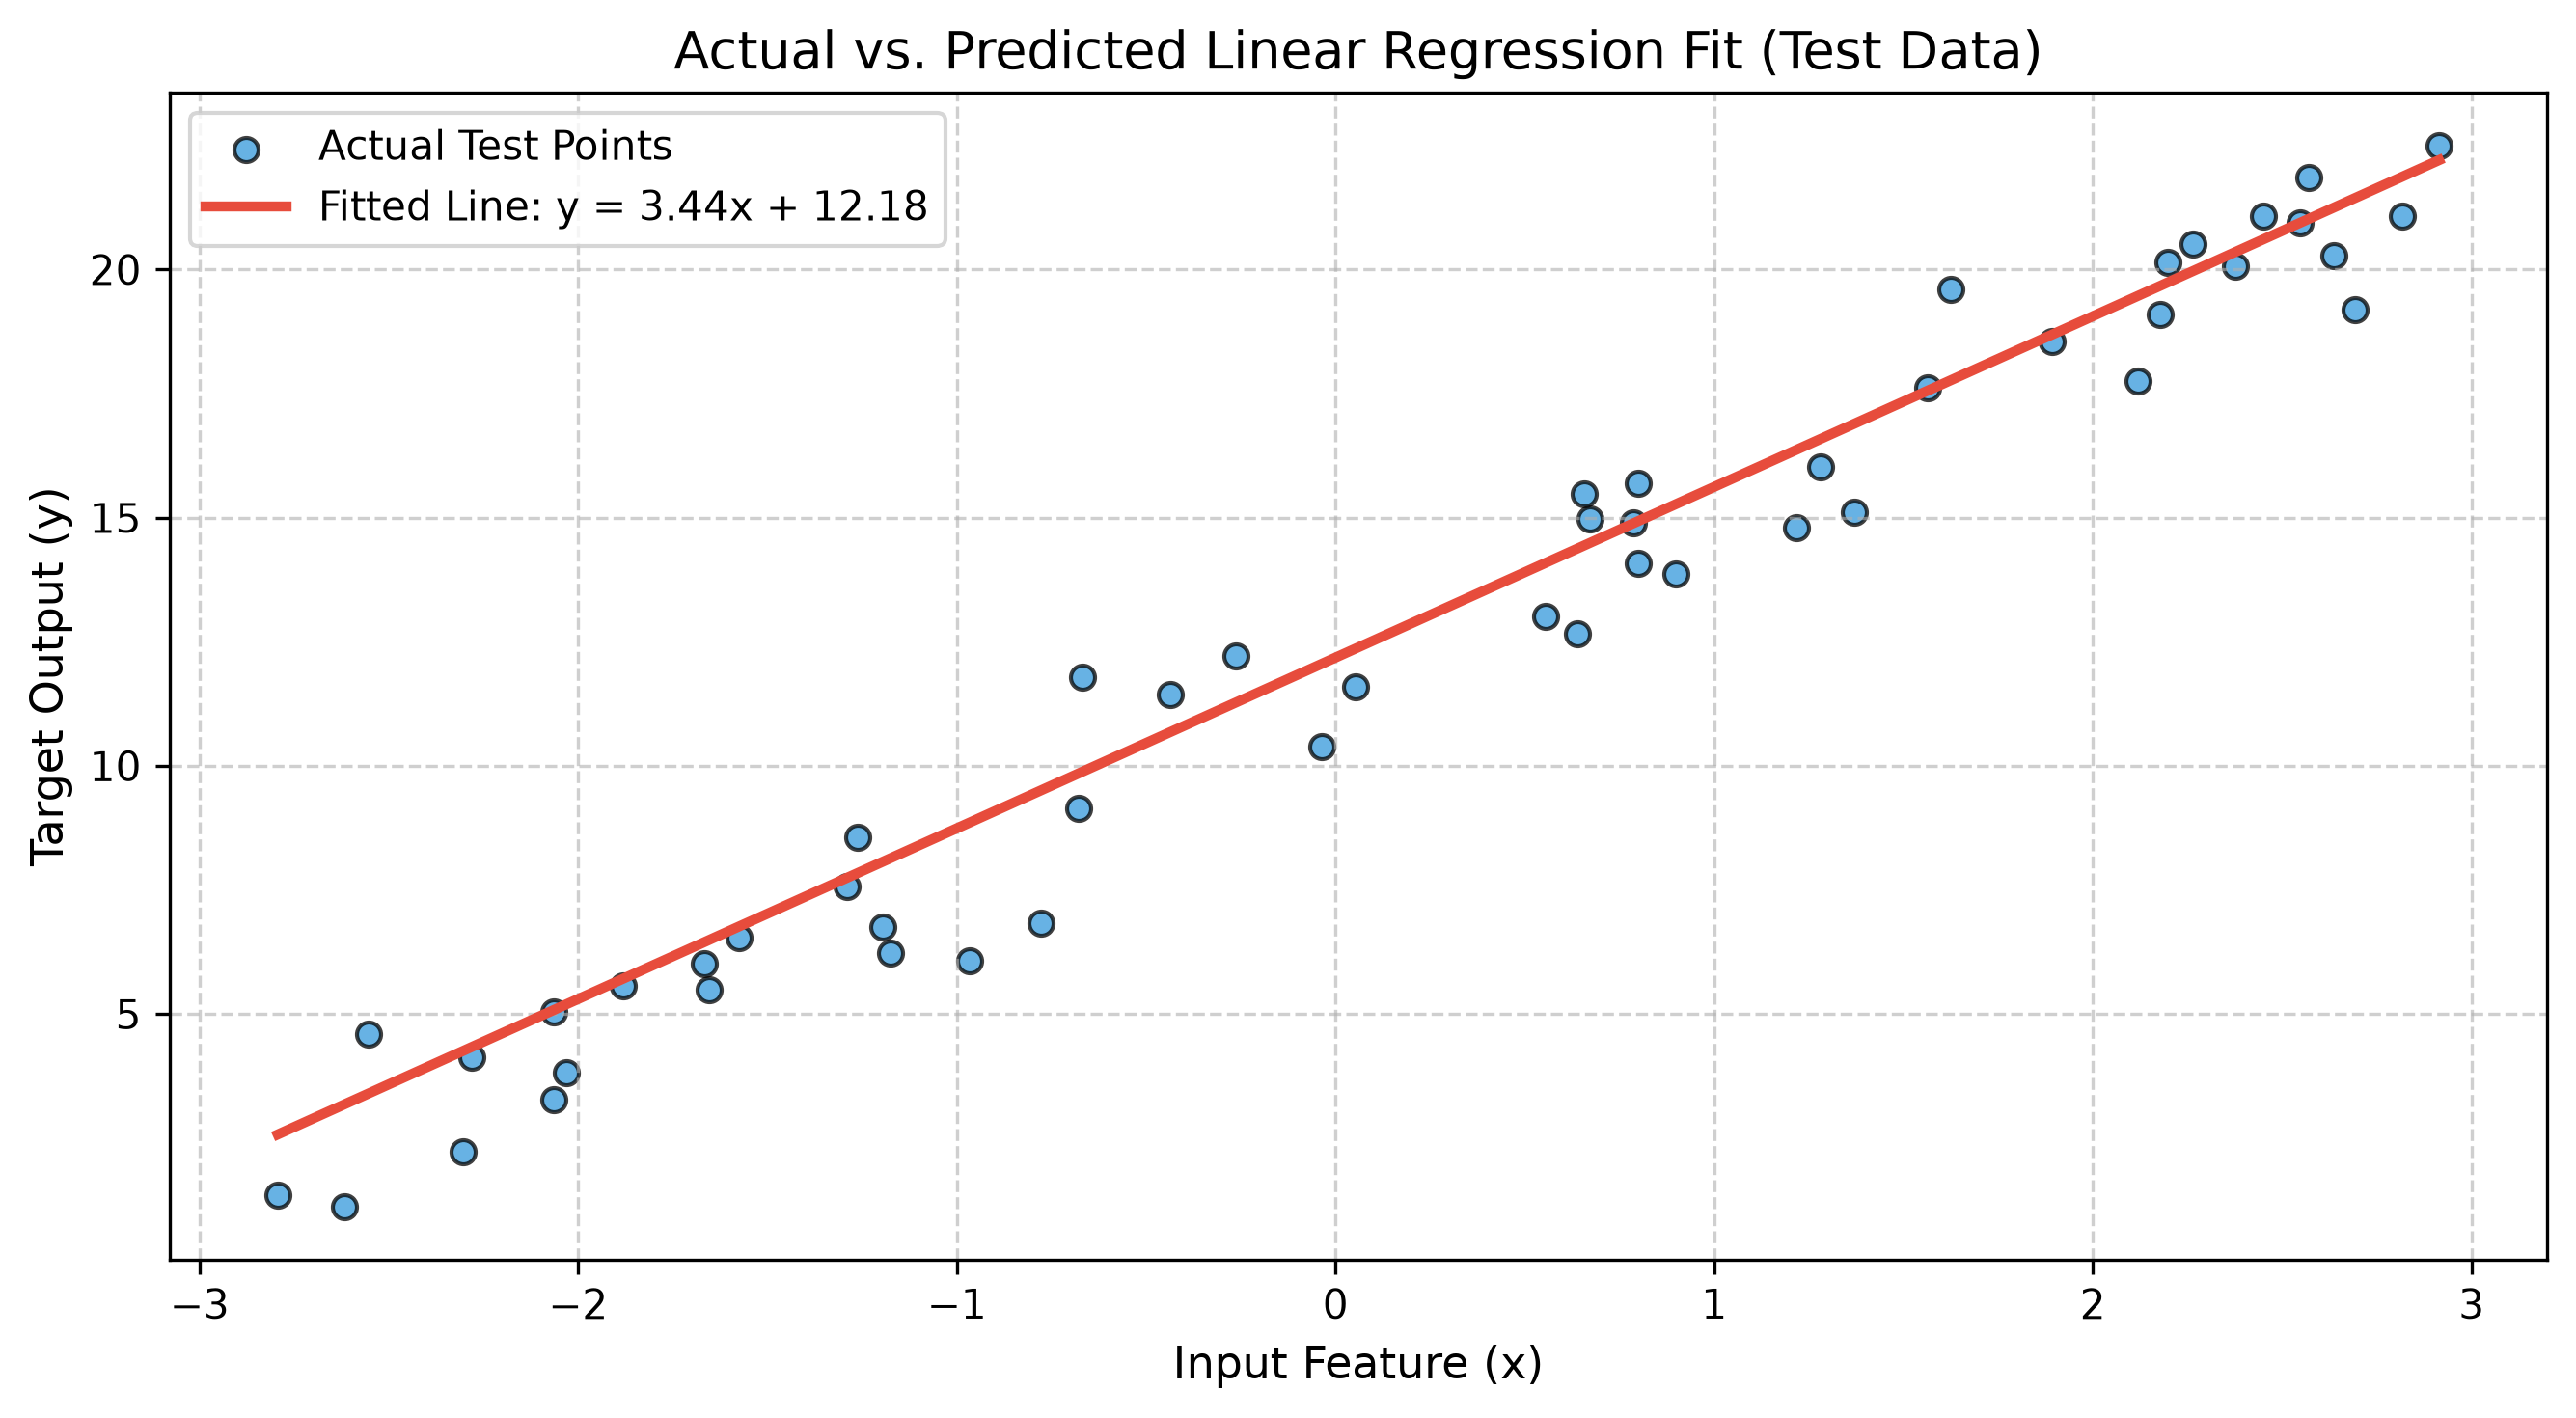

Actual vs Predicted plot saved to: outputs/actual_vs_predicted.png


In [10]:
# Display sample actual vs predicted values
comparison_df = pd.DataFrame({
    "Input (x)": X_test[:10].flatten().numpy().round(3),
    "Actual Target (y)": y_test[:10].flatten().numpy().round(3),
    "Predicted (y_hat)": y_test_pred[:10].flatten().numpy().round(3),
    "Residual Error": (y_test[:10] - y_test_pred[:10]).flatten().numpy().round(3)
})
display(comparison_df)

# Plot actual vs predicted scatter and regression line
plt.figure(figsize=(9, 5), dpi=300)
plt.scatter(X_test.numpy(), y_test.numpy(), color="#3498db", label="Actual Test Points", alpha=0.75, edgecolors="k")

# Generate line coordinates
x_line = np.linspace(X_test.min().item(), X_test.max().item(), 100)
y_line = learned_w * x_line + learned_b
plt.plot(x_line, y_line, color="#e74c3c", lw=2.5, label=f"Fitted Line: y = {learned_w:.2f}x + {learned_b:.2f}")

plt.title("Actual vs. Predicted Linear Regression Fit (Test Data)", fontsize=13)
plt.xlabel("Input Feature (x)", fontsize=11)
plt.ylabel("Target Output (y)", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

reg_plot_path = OUTPUT_DIR / "actual_vs_predicted.png"
plt.savefig(reg_plot_path)
plt.show()
print(f"Actual vs Predicted plot saved to: {reg_plot_path}")


---
### 11. Conceptual Roles in Deep Learning Optimization

| Component | Mathematical Notation | Computational Role in Training Loop |
| :--- | :---: | :--- |
| **Weight ($W$)** | $W \in \mathbb{R}^{d_{in} \times d_{out}}$ | Multiplicative scaling factor representing feature sensitivity/importance. |
| **Bias ($b$)** | $b \in \mathbb{R}^{d_{out}}$ | Additive threshold allowing the regression line to shift off origin. |
| **Loss Function** | $\mathcal{L}(y, \hat{y})$ | Scalar objective quantifying penalty for empirical discrepancy. |
| **Gradients** | $\frac{\partial \mathcal{L}}{\partial W}, \frac{\partial \mathcal{L}}{\partial b}$ | Direction of steepest ascent in loss landscape computed by Autograd. |
| **Optimizer** | $\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}$ | Algorithm updating parameters along the negative gradient vector. |


---
### 12. Summary and Key Takeaways

1. **PyTorch Linear Layers**: `nn.Linear` maintains learnable weight and bias parameters initialized automatically.
2. **Gradient-Based Convergence**: Over 150 epochs, SGD drove the Mean Squared Error from high initial values down to $\approx 1.54$, recovering $W=3.44$ (true 3.5) and $b=12.18$ (true 12.0).
3. **Generalization Performance**: The model achieved an $R^2$ score of $96.19\%$ on unseen test data, verifying strong linear generalization without overfitting.
